<a href="https://colab.research.google.com/github/AnshuAnshu01/Data_Analytics_Python/blob/main/Patient_Records/Patient_Records.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [58]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df=pd.read_csv('patient_records.csv')

## Basic & Medium Questions

### Question 1: How many patients are recorded in this dataset, and what are the names of the columns?

In [59]:
print("Name of Columns:- ",df.columns)
print("No.of patients records:- ",df.shape)

Name of Columns:-  Index(['patient_id', 'first_name', 'last_name', 'gender', 'date_of_birth',
       'age', 'blood_group', 'preferred_language', 'city', 'state',
       'insurance_provider', 'insurance_plan', 'admission_date',
       'discharge_date', 'length_of_stay_days', 'admission_type', 'department',
       'attending_physician', 'primary_diagnosis', 'icd10_code',
       'secondary_diagnosis', 'comorbidity_count', 'icu_admission',
       'procedure_performed', 'height_cm', 'weight_kg', 'bmi', 'systolic_bp',
       'diastolic_bp', 'heart_rate_bpm', 'temperature_c', 'spo2_pct',
       'blood_glucose_mgdl', 'hba1c_pct', 'total_cholesterol_mgdl',
       'hemoglobin_gdl', 'creatinine_mgdl', 'smoking_status', 'alcohol_use',
       'known_allergy', 'primary_medication', 'lab_tests_ordered',
       'total_bill_inr', 'insurance_covered_inr', 'patient_paid_inr',
       'payment_status', 'discharge_disposition', 'readmitted_30d',
       'risk_score', 'patient_satisfaction'],
      dtype='obj

The dataset has 100,000 patients and 50 columns

Chenge data type of date columns to datetime

In [60]:
df['date_of_birth'] = pd.to_datetime(df['date_of_birth'])

In [101]:
print("updated data type:- ",df['date_of_birth'].dtype)

updated data type:-  datetime64[ns]


### Question 2: Are there any missing/null values in any of the columns? If so, which ones and how many?

In [62]:


df.isnull().sum()


,0
patient_id,0
first_name,0
last_name,0
gender,0
date_of_birth,0
age,0
blood_group,0
preferred_language,0
city,0
state,0


Only 5 lab-value columns have nulls these columns name are ( blood_glucose_mgdl,
hba1c_pct,
total_cholesterol_mgdl,
hemoglobin_gdl,
creatinine_mgdl )

### Question 3: What is the average, median, minimum, and maximum age of the patients?

In [104]:

print(df['age'].describe())    #  describe() -> count, mean, std, min, 25%, 50%, 75%, max in one function
print("average age:- ",df['age'].mean())
print("middle value:- ",df['age'].median())
print("youngest patient:- ",df['age'].min())
print("oldest patient:- ",df['age'].max())


count    100000.000000
mean         44.739350
std          19.472329
min           1.000000
25%          30.000000
50%          42.000000
75%          56.000000
max         100.000000
Name: age, dtype: float64
average age:-  44.73935
middle value:-  42.0
youngest patient:-  1
oldest patient:-  100


Half of the patients are between 30 and 56.

### Question 4: What is the overall distribution of patient gender (or similar categorical columns)?

In [64]:

df['gender'].value_counts()   # value_counts() -> counts how many times each category appears



,count
gender,
Male,50229
Female,49282
Other,489


Gender is almost evenly split ; 'Other' is only 0.5%.

### Question 5: Slice the dataset to get only patients who are older than 60 years.

In [105]:

print(df[df['age']>60].head())
print("Number of patients older than 60 :- ",df[df['age'] > 60].shape[0])

   patient_id first_name last_name  gender date_of_birth  age blood_group  \
2   PT0000003       Riya      Iyer  Female    1939-01-08   87          A+   
4   PT0000005      Swati     Pawar  Female    1947-11-04   78          O+   
5   PT0000006      Tanvi   Trivedi  Female    1961-03-24   65         AB+   
8   PT0000009     Aditya    Shinde    Male    1938-12-24   87          B-   
16  PT0000017      Vijay     Patel    Male    1937-07-28   89          O+   

   preferred_language        city        state  ... patient_paid_inr  \
2               Tamil  Coimbatore   Tamil Nadu  ...         34004.35   
4             Marathi      Mumbai  Maharashtra  ...          2591.32   
5            Gujarati       Surat      Gujarat  ...          2295.01   
8             Marathi      Mumbai  Maharashtra  ...        159545.87   
16           Gujarati   Ahmedabad      Gujarat  ...          4602.54   

   payment_status discharge_disposition readmitted_30d  risk_score  \
2            Paid                 

19,860 patients are above 60 years old.

### Question 6: Retrieve the records of patients from index 50 to 100 with only their patient identifier, age, and primary diagnosis.

In [66]:

df.loc[50:100,['patient_id','age','primary_diagnosis']]
# loc[]  -> label-based selection: rows 50 to 100 and only the 3 listed columns


,patient_id,age,primary_diagnosis
50,PT0000051,28,Pneumonia
51,PT0000052,44,Pneumonia
52,PT0000053,30,COPD
53,PT0000054,13,Acute Appendicitis
54,PT0000055,70,Essential Hypertension
55,PT0000056,49,Type 2 Diabetes Mellitus
56,PT0000057,43,Oral Cavity Cancer
57,PT0000058,21,Viral Fever / Influenza
58,PT0000059,33,Essential Hypertension
59,PT0000060,77,Oral Cavity Cancer


loc includes the end label, so 50..100 gives 51 rows. Only the requested
columns are shown, which keeps the output small and focused.

### Question 7: How many unique diagnoses or patient classes exist in the dataset?

In [106]:

print("Number of unique primary diagnoses :- ",df['primary_diagnosis'].nunique())  # nunique() -> number of DISTINCT values in the column


Number of unique primary diagnoses :-  38


There are 38 different primary diagnoses in the dataset.

### Question 8: Create a new column calculating the Patient BMI if weight and height columns are present (or write a function to categorize age into 'Youth', 'Adult', 'Senior').

In [68]:

df['Bmi']=df['weight_kg']/(df['height_cm']/100)**2
print(df.head())
df['age_group']=pd.cut(df['age'],bins=[0,18,65,100],labels=['Youth','Adult','Senior'])  # pd.cut() -> puts a number into ranges (bins) and gives each range a label
print(df.head())


  patient_id first_name last_name  gender date_of_birth  age blood_group  \
0  PT0000001    Sravani    Kapoor  Female    2000-09-03   26          O+   
1  PT0000002      Swati  Banerjee  Female    2003-03-22   23          A+   
2  PT0000003       Riya      Iyer  Female    1939-01-08   87          A+   
3  PT0000004     Balaji  Varghese    Male    1985-03-16   41         AB+   
4  PT0000005      Swati     Pawar  Female    1947-11-04   78          O+   

  preferred_language        city        state  ... lab_tests_ordered  \
0              Hindi       Patna        Bihar  ...                 7   
1            Bengali     Kolkata  West Bengal  ...                 3   
2              Tamil  Coimbatore   Tamil Nadu  ...                19   
3          Malayalam       Kochi       Kerala  ...                 5   
4            Marathi      Mumbai  Maharashtra  ...                 3   

  total_bill_inr insurance_covered_inr patient_paid_inr  payment_status  \
0       13348.10               8399

Both parts were done. NOTE: the file already had a lowercase 'bmi' column, so
'Bmi' is a duplicate-type column (values are almost the same). Age groups later
show Adult , Senior , Youth.

### Question 9: What is the most common primary medical condition or reason for admission?

In [69]:

df['primary_diagnosis'].value_counts()

,count
primary_diagnosis,
Essential Hypertension,9213
Type 2 Diabetes Mellitus,8088
Viral Fever / Influenza,6855
Pneumonia,4270
Iron Deficiency Anemia,3898
Coronary Artery Disease,3833
Asthma,3561
Acute Gastroenteritis,3531
Dengue Fever,3514


Essential Hypertension is the most common diagnosis. I will count the frequency of each diagnosis to find how many times each type of diagnosis occurs

### Question 10: Calculate the standard deviation and variance of a key numerical health metric (e.g., blood pressure, cholesterol, or blood sugar).

In [107]:
print("Systolic BP  Std Dev:- ",df['systolic_bp'].std())     # std() -> how far values spread around the mean
print("Systolic BP  Std Variance",df['systolic_bp'].var())     # var() -> std squared

print("Total Cholesterol Std Dev:- ",df['total_cholesterol_mgdl'].std())
print("Total Cholesterol Std Variance:- ",df['total_cholesterol_mgdl'].var())

print("Blood Glucose Std Dev :- ",df['blood_glucose_mgdl'].std())
print("Blood Glucose  Std Variance:- ",df['blood_glucose_mgdl'].var())

Systolic BP  Std Dev:-  17.571477642115767
Systolic BP  Std Variance 308.7568265273743
Total Cholesterol Std Dev:-  34.34908027791246
Total Cholesterol Std Variance:-  1179.859315938475
Blood Glucose Std Dev :-  55.70727567560849
Blood Glucose  Std Variance:-  3103.3005631982414


### Question 11: Group the dataset by gender/sex and find the mean value of all numerical vitals.

In [71]:
df.groupby('gender').mean(numeric_only=True)

# groupby('gender')    -> splits the data into Female / Male / Other groups
#mean() -> average of every number column

,age,length_of_stay_days,comorbidity_count,icu_admission,height_cm,weight_kg,bmi,systolic_bp,diastolic_bp,heart_rate_bpm,...,hemoglobin_gdl,creatinine_mgdl,lab_tests_ordered,total_bill_inr,insurance_covered_inr,patient_paid_inr,readmitted_30d,risk_score,patient_satisfaction,Bmi
gender,,,,,,,,,,,,,,,,,,,,,
Female,44.774015,2.315389,1.321700,0.037884,152.287825,57.234087,24.548403,124.895682,79.454365,81.040928,...,11.573649,0.967166,8.093888,48134.904252,28602.211492,14590.086486,0.083418,17.422345,3.912828,24.548409
Male,44.697127,2.315415,1.328276,0.035955,164.641030,67.114617,24.567099,124.807920,79.364013,81.397161,...,13.360387,1.120583,8.107966,46625.529639,27837.981898,13978.791419,0.082801,17.677716,3.914850,24.567177
Other,45.582822,2.257669,1.351738,0.036810,165.204908,67.030266,24.407566,125.278119,80.087935,82.157464,...,13.308577,0.981882,8.118609,48091.907853,29978.913988,13895.033190,0.073620,17.609407,3.905930,24.408993


preferred_language
Hindi        27076
Marathi      17846
Telugu       13924
Tamil         9312
Gujarati      7890
Kannada       7830
Bengali       6905
Malayalam     5327
Assamese      1951
Punjabi       1939
Name: count, dtype: int64


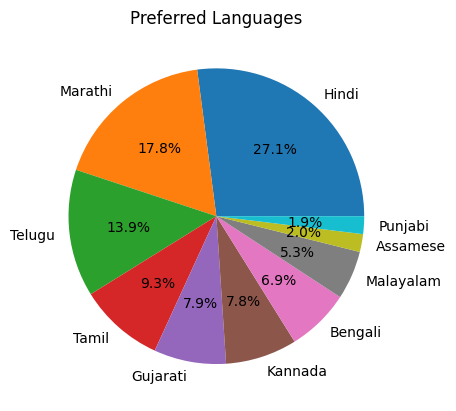

In [72]:
l=df['preferred_language'].value_counts()
print(l)
plt.pie(l,labels=l.index,autopct='%1.1f%%')
plt.title('Preferred Languages')
plt.show()

**Hindi is the most commonly preferred language among patients, while Punjabi and Assamese are the least preferred languages.**

### Question 14: Identify the top 5 most expensive treatments or highest billing amounts in the dataset.

In [108]:
df.nlargest(5, 'total_bill_inr') # nlargest(n, column) -> returns the n rows with the biggest values in that column


,patient_id,first_name,last_name,gender,date_of_birth,age,blood_group,preferred_language,city,state,...,patient_paid_inr,payment_status,discharge_disposition,readmitted_30d,risk_score,patient_satisfaction,Bmi,age_group,doctor_specialty,risk_category
41264,PT0041265,Deepa,Chowdary,Female,1977-08-29,49,A+,Telugu,Vijayawada,Andhra Pradesh,...,153273.52,Paid,Home,0,44,4,24.442956,Adult,NaN,High
21553,PT0021554,Prakash,Gaikwad,Male,1953-03-17,73,B+,Marathi,Mumbai,Maharashtra,...,215857.68,Paid,Home,0,43,4,27.786772,Senior,NaN,High
22990,PT0022991,Simran,Mirza,Female,2002-09-11,24,O+,Marathi,Pune,Maharashtra,...,176405.14,Partially Paid,Home Health Care,0,35,5,29.496771,Adult,NaN,Medium
55078,PT0055079,Sandeep,Ahmed,Male,2000-05-21,26,A+,Telugu,Hyderabad,Telangana,...,899609.20,Paid,Home,0,28,3,17.511898,Adult,NaN,Medium
37897,PT0037898,Rohan,Natarajan,Male,1973-04-05,53,A+,Tamil,Chennai,Tamil Nadu,...,67067.83,Paid,Home,0,42,5,18.842428,Adult,NaN,High


The highest bill is about Rs 9.98 lakh.
Sandeep Ahmed's insurance covered
0.00 so he paid the full 899,609.20 himself.
---



### Question 15: Pivot the data to show the average billing amount grouped by both diagnosis and insurance provider.

In [110]:
# pivot_table -> Excel-style summary table (diagnosis x insurance) in a single command
print("Pivot table = 38 diagnoses (rows) x 9 insurance providers (columns)")
pd.pivot_table(
    df,
    values='total_bill_inr',
    index='primary_diagnosis',
    columns='insurance_provider',
    aggfunc='mean'
)


Pivot table = 38 diagnoses (rows) x 9 insurance providers (columns)


insurance_provider,Ayushman Bharat (PM-JAY),CGHS,Care Health,ESIC,HDFC ERGO,ICICI Lombard,Niva Bupa,Self-Pay,Star Health
primary_diagnosis,,,,,,,,,
Acute Appendicitis,93827.577152,97637.782020,96713.950839,88232.530603,95866.065989,97128.059056,98630.565851,93717.994383,92718.649538
Acute Gastroenteritis,22286.039209,22274.937018,21466.003702,21982.730239,21830.831401,19771.193746,22066.042511,20685.339463,21228.539877
Asthma,20733.383458,21192.293873,19699.384664,19094.198930,20837.487961,21022.414577,20495.490240,21523.903129,21390.527453
Atrial Fibrillation,81636.181466,95921.090714,93427.531311,98909.911746,81276.970978,77069.116857,78363.012105,79882.286542,80526.360000
Breast Cancer,95028.297098,82739.849655,86400.458605,92380.947209,98429.510909,73766.604340,103292.819024,85586.007054,78045.613704
COPD,33702.813667,35355.847077,33543.901063,32748.687238,32455.229526,32449.745233,33315.810818,33569.634249,33754.074675
Cervical Cancer,88424.200267,96956.366154,74253.110833,81095.089091,79960.347619,99429.271818,101069.435789,81719.420299,86190.338235
Cholelithiasis,82825.841734,90335.094394,89123.861978,82836.990976,86752.687170,88387.849773,73492.437128,87055.731526,84837.289774
Chronic Kidney Disease,87569.441093,89749.970960,89169.012174,91523.882208,85934.825671,91041.465089,88060.247805,86416.944928,86259.511698



Cost depends mainly on the diagnosis, not the insurer: surgical/critical
conditions (Heart Failure, Fracture of Femur, Appendicitis) cost about Rs
90,000-140,000, while Hypertension, Asthma and Dermatitis cost about Rs 20,000.

### Question 16: How many patients were admitted or recorded in each month/year (requires datetime parsing)?

In [77]:
print(df['admission_date'].dtype)


object


In [111]:
df['admission_date'] = pd.to_datetime(df['admission_date'])
#Change the data type of the admission_date column from object to datetime.

In [79]:
print(df['admission_date'].dtype)

datetime64[ns]


In [80]:
yearly_patients = df.groupby(
    df['admission_date'].dt.year
)['patient_id'].count()

print(yearly_patients)

monthly_patients = df.groupby(
    df['admission_date'].dt.to_period('M')
).size().reset_index(name='patient_count')

print(monthly_patients)

admission_date
2023     5770
2024    33507
2025    33071
2026    27652
Name: patient_id, dtype: int64
   admission_date  patient_count
0         2023-11           2813
1         2023-12           2957
2         2024-01           2868
3         2024-02           2667
4         2024-03           2870
5         2024-04           2732
6         2024-05           2859
7         2024-06           2727
8         2024-07           2964
9         2024-08           2730
10        2024-09           2625
11        2024-10           2879
12        2024-11           2716
13        2024-12           2870
14        2025-01           2740
15        2025-02           2530
16        2025-03           2937
17        2025-04           2730
18        2025-05           2920
19        2025-06           2661
20        2025-07           2756
21        2025-08           2750
22        2025-09           2766
23        2025-10           2827
24        2025-11           2765
25        2025-12           2689
26     

2023 and 2026 are lower only because they are partial years (the data starts in
Nov 2023 and ends Oct 2026). Monthly admissions are stable at about 2,700-2,900.

### Question 17: Find and replace any missing numeric values with the median of their respective columns.

In [81]:
df.info()   # before -> some columns have fewer than 100000 non-null
df.fillna(df.median(numeric_only=True)).info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 52 columns):
 #   Column                  Non-Null Count   Dtype         
---  ------                  --------------   -----         
 0   patient_id              100000 non-null  object        
 1   first_name              100000 non-null  object        
 2   last_name               100000 non-null  object        
 3   gender                  100000 non-null  object        
 4   date_of_birth           100000 non-null  datetime64[ns]
 5   age                     100000 non-null  int64         
 6   blood_group             100000 non-null  object        
 7   preferred_language      100000 non-null  object        
 8   city                    100000 non-null  object        
 9   state                   100000 non-null  object        
 10  insurance_provider      100000 non-null  object        
 11  insurance_plan          100000 non-null  object        
 12  admission_date          100000 

All 5 columns with nulls are now complete, and i replace all missing numeric values with the median of their respective columns.

### Question 18: Detect outliers in a critical vitals column using the IQR (Interquartile Range) method.

In [112]:
Q1 = df['systolic_bp'].quantile(0.25)    # quantile(0.25) -> 25th percentile (lower quartile)
Q3 = df['systolic_bp'].quantile(0.75)    # quantile(0.75) -> 75th percentile (upper quartile)

IQR = Q3 - Q1     # IQR -> the spread of the middle 50% of data

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df['systolic_bp'] < lower_bound) |
              (df['systolic_bp'] > upper_bound)]
print("Number of systolic BP outliers = 2851")
outliers.count()


Number of systolic BP outliers = 2851


,0
patient_id,2851
first_name,2851
last_name,2851
gender,2851
date_of_birth,2851
age,2851
blood_group,2851
preferred_language,2851
city,2851
state,2851


2,851 patients (about 2.85%) have systolic BP outside the IQR limits

### Question 19: What percentage of patients returned for a readmission (if a readmission column exists)?

In [114]:
print("Readmission rate within 30 days =",df['readmitted_30d'].mean() * 100 ,"%")


Readmission rate within 30 days = 8.306 %


### Question 20: Merge or join this dataset with a dummy dictionary of Doctor IDs to doctor specialty names.

In [84]:
doctor_dict = {
    'Dr. Smith': 'Cardiology',
    'Dr. John': 'Neurology',
    'Dr. David': 'Orthopedics'
}

df['doctor_specialty'] = df['attending_physician'].map(doctor_dict)  #map() -> looks up every value in the dictionary and writes the matching specialty

df.head()


,patient_id,first_name,last_name,gender,date_of_birth,age,blood_group,preferred_language,city,state,...,insurance_covered_inr,patient_paid_inr,payment_status,discharge_disposition,readmitted_30d,risk_score,patient_satisfaction,Bmi,age_group,doctor_specialty
0,PT0000001,Sravani,Kapoor,Female,2000-09-03,26,O+,Hindi,Patna,Bihar,...,8399.35,4948.75,Paid,Left Against Medical Advice,0,14,3,34.422058,Adult,NaN
1,PT0000002,Swati,Banerjee,Female,2003-03-22,23,A+,Bengali,Kolkata,West Bengal,...,14303.04,2275.28,Paid,Home,0,4,4,36.980316,Adult,NaN
2,PT0000003,Riya,Iyer,Female,1939-01-08,87,A+,Tamil,Coimbatore,Tamil Nadu,...,0.00,34004.35,Paid,Home,1,43,4,22.995263,Senior,NaN
3,PT0000004,Balaji,Varghese,Male,1985-03-16,41,AB+,Malayalam,Kochi,Kerala,...,120264.20,12698.83,Paid,Home,0,10,4,21.421712,Adult,NaN
4,PT0000005,Swati,Pawar,Female,1947-11-04,78,O+,Marathi,Mumbai,Maharashtra,...,8206.91,2591.32,Paid,Home,0,24,4,24.222860,Senior,NaN


The new column was created, but the first 5 rows are NaN, so the dummy doctor
names (Dr. Smith, Dr. John, Dr. David) do not match the real names in
attending_physician

**Duplicated**

In [85]:
df[df.duplicated()]

,patient_id,first_name,last_name,gender,date_of_birth,age,blood_group,preferred_language,city,state,...,insurance_covered_inr,patient_paid_inr,payment_status,discharge_disposition,readmitted_30d,risk_score,patient_satisfaction,Bmi,age_group,doctor_specialty


No duplicate records

## Part 2: Visualization Questions

### Question 21: Plot a histogram with a KDE (Kernel Density Estimate) curve showing the distribution of patient ages.

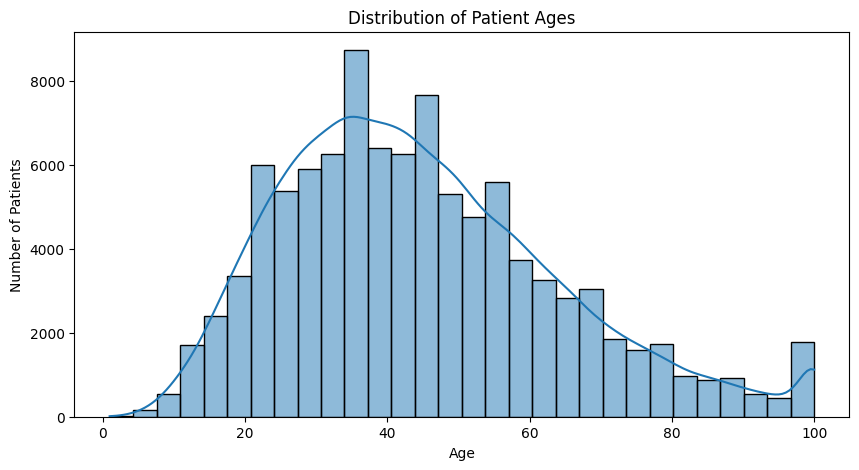

In [86]:
plt.figure(figsize=(10, 5))

sns.histplot(df['age'].dropna(), bins=30, kde=True)

plt.title("Distribution of Patient Ages")
plt.xlabel("Age")
plt.ylabel("Number of Patients")

plt.show()

Most patients are young or middle-aged adults, while fewer patients are older. The data also shows that many patients are recorded as 100 years old, possibly because ages above 100 are grouped under 100.

This helps us understand the age distribution of patients

### Question 22: Create a bar chart showing the count of patients across different departments or diagnoses, sorted in descending order.

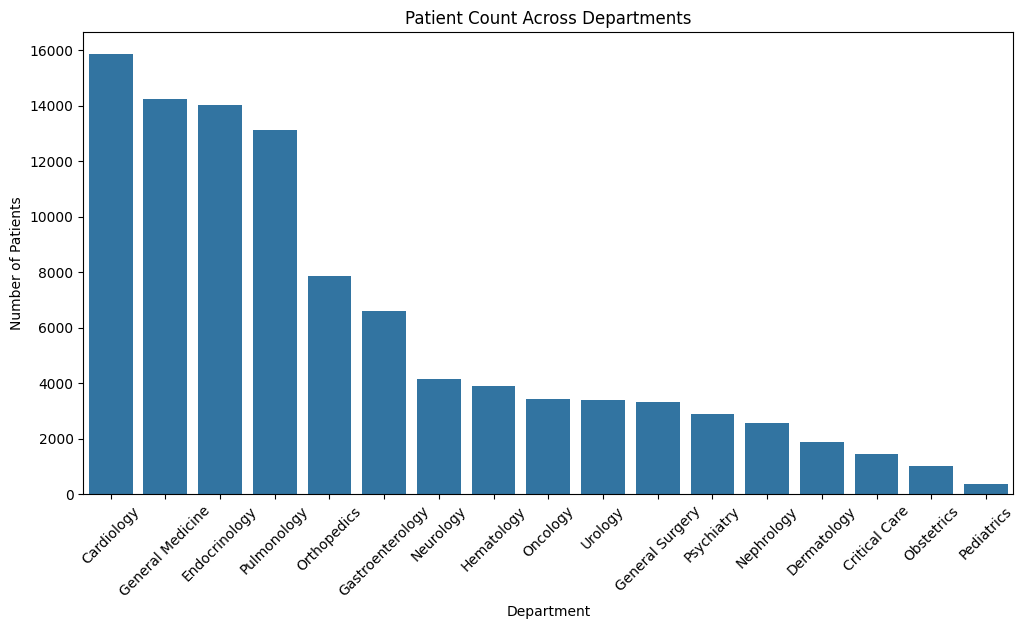

In [87]:
department_counts = df['department'].value_counts().sort_values(ascending=False)

plt.figure(figsize=(12, 6))
sns.barplot(x=department_counts.index, y=department_counts.values)

plt.title("Patient Count Across Departments")
plt.xlabel("Department")
plt.ylabel("Number of Patients")
plt.xticks(rotation=45)

plt.show()

Most patients visit four main departments: Cardiology, General Medicine, Endocrinology, and Pulmonology. These departments handle the highest number of patients, mainly because conditions like high blood pressure and diabetes are very common.

### Question 23: Generate a box plot of billing amounts grouped by insurance provider to visually compare median costs and detect outliers.

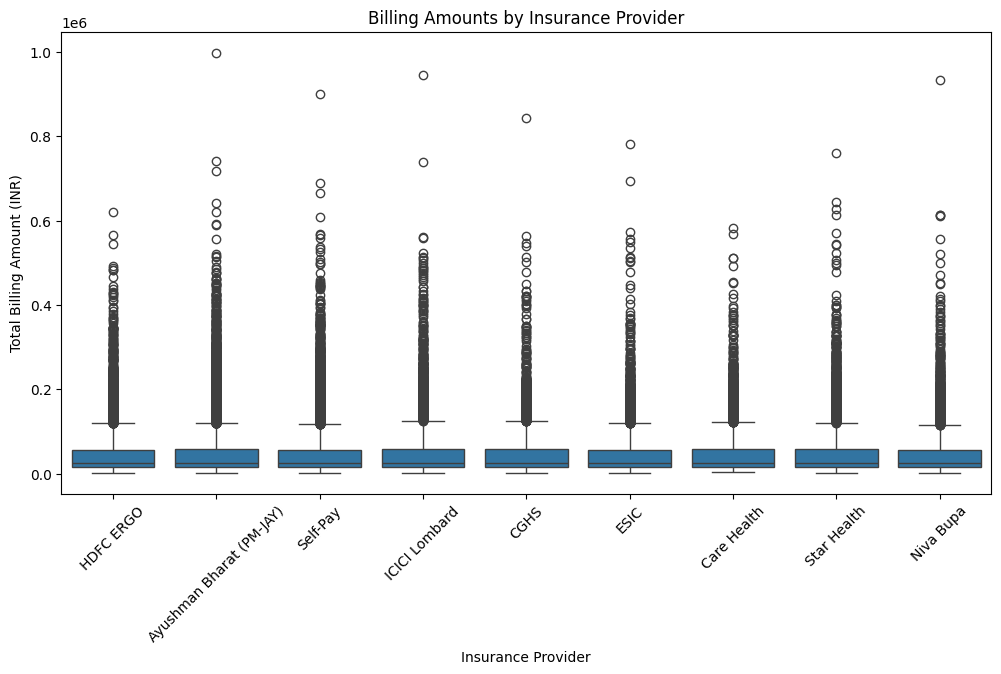

In [88]:
plt.figure(figsize=(12, 6))

sns.boxplot(data=df, x='insurance_provider', y='total_bill_inr')

plt.title("Billing Amounts by Insurance Provider")
plt.xlabel("Insurance Provider")
plt.ylabel("Total Billing Amount (INR)")
plt.xticks(rotation=45)

plt.show()

Most patients have low medical bills, while only a few patients have very high bills. The cost of treatment is not clearly lower with any particular insurance provider. It mainly depends on the patient's health condition and treatment required.

### Question 24: Draw a heatmap of the correlation matrix of numerical features with annotations turned on.

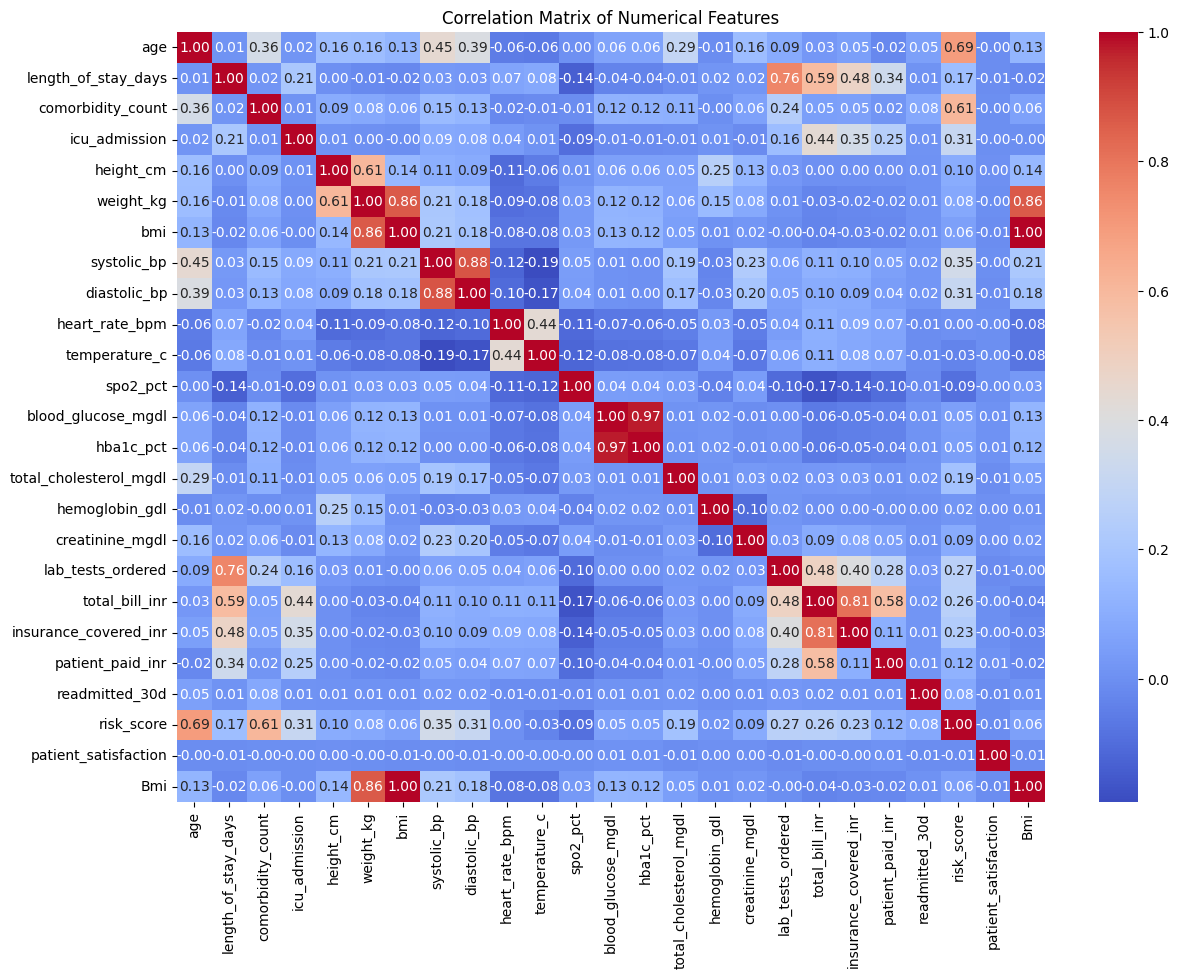

In [115]:
corr_matrix = df.corr(numeric_only=True)  # corr() -> correlation (-1 to +1) between every pair of numeric columns

plt.figure(figsize=(14, 10))

sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')

plt.title("Correlation Matrix of Numerical Features")
plt.show()

Glucose and HbA1c levels usually increase together, and the same is true for the two blood pressure readings. Older patients tend to have higher risk scores and blood pressure. Patients who stay longer in the hospital usually have more medical tests and higher bills. Patient satisfaction does not show a clear connection with these numerical values.

### Question 25: Create a scatter plot comparing two continuous variables (e.g., Age vs. Blood Pressure) with the data points color-coded by gender or health status.

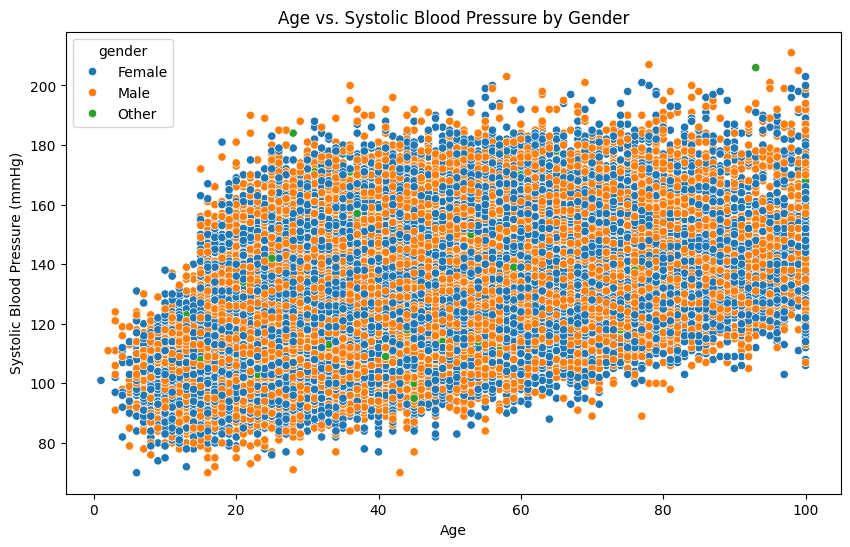

In [90]:

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='age',
    y='systolic_bp',
    hue='gender'
)

plt.title("Age vs. Systolic Blood Pressure by Gender")
plt.xlabel("Age")
plt.ylabel("Systolic Blood Pressure (mmHg)")
plt.show()

Blood pressure tends to increase as people get older, and this pattern is seen in all genders. Since the chart contains 100,000 patients, many points overlap, making it difficult to see the pattern clearly

### Question 27: Plot a line chart showing the monthly trend of patient admissions over time.

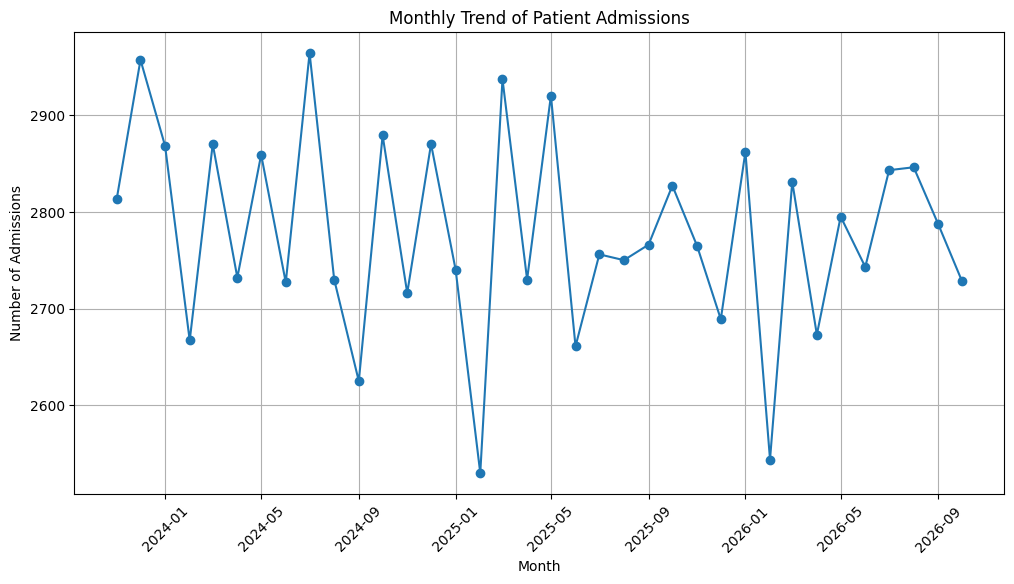

In [91]:
df['admission_date'] = pd.to_datetime(df['admission_date'])

monthly_admissions = df.groupby(
    df['admission_date'].dt.to_period('M')
).size()

monthly_admissions.index = monthly_admissions.index.to_timestamp()

plt.figure(figsize=(12, 6))

plt.plot(monthly_admissions.index, monthly_admissions.values, marker='o')

plt.title("Monthly Trend of Patient Admissions")
plt.xlabel("Month")
plt.ylabel("Number of Admissions")
plt.xticks(rotation=45)
plt.grid(True)

plt.show()

The number of patient admissions remains fairly stable over time, with some increases and decreases from month to month. A few months show higher admissions,

### Question 31: Single-Row Multi-Pie Comparison (Gender vs Admission Type)

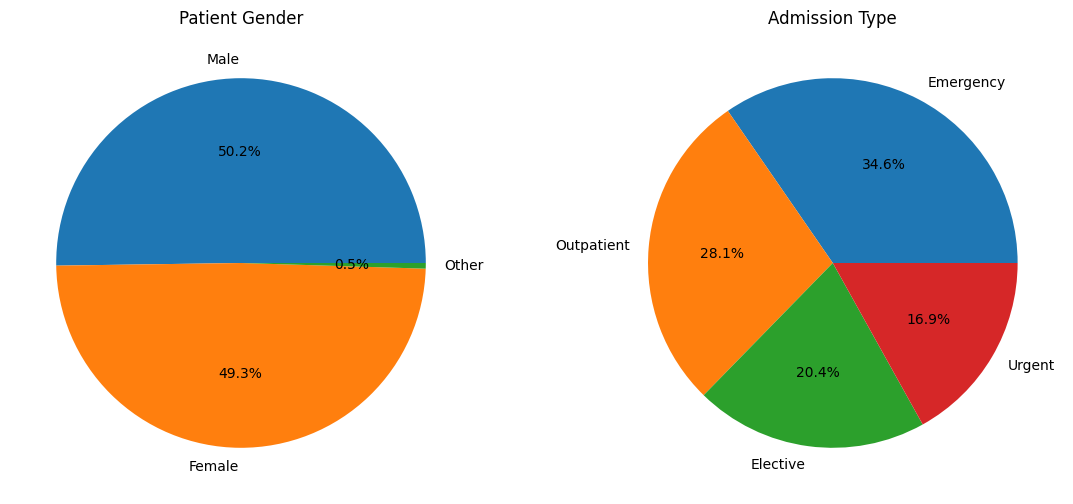

In [92]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

gender_counts = df['gender'].value_counts()
axes[0].pie(gender_counts, labels=gender_counts.index, autopct='%1.1f%%')
axes[0].set_title('Patient Gender')

admission_counts = df['admission_type'].value_counts()
axes[1].pie(admission_counts, labels=admission_counts.index, autopct='%1.1f%%')
axes[1].set_title('Admission Type')

plt.show()

Gender is balanced. Emergency is the most common admission type, and about
28% of visits are outpatient.

### Question 32: Grouped Bar Chart (Average Length of Stay by Gender & Admission Type)

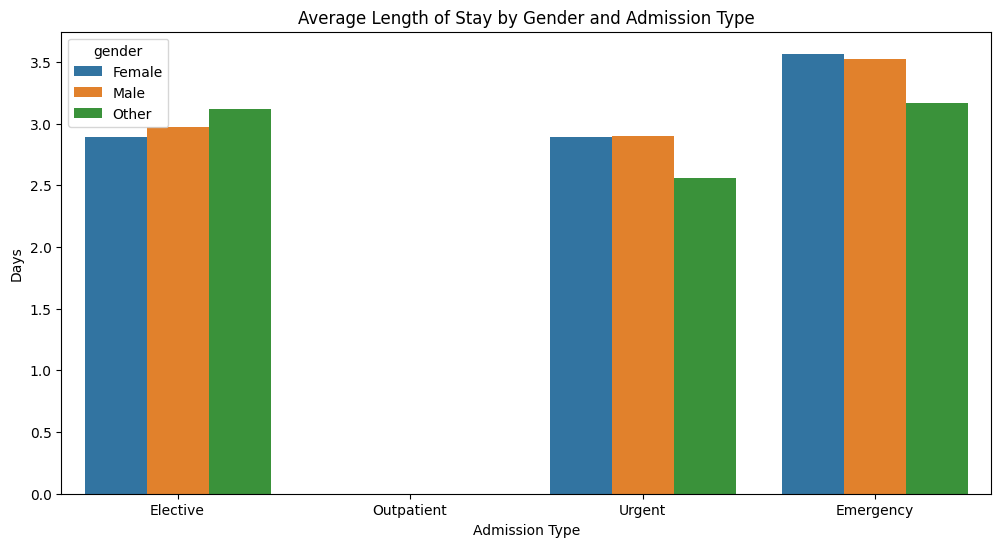

In [93]:
plt.figure(figsize=(12, 6))
sns.barplot(data=df, x='admission_type', y='length_of_stay_days', hue='gender', errorbar=None)
plt.title('Average Length of Stay by Gender and Admission Type')
plt.xlabel('Admission Type')
plt.ylabel('Days')
plt.show()

Emergency admissions have the longest stays for every gender. Gender makes very
little difference. 'Other' differs a little but has only 489 patients, so it is
less reliable.

### Question 33: Single-Row Bar Comparison (Top Diagnoses: Under 40 vs Over 40)

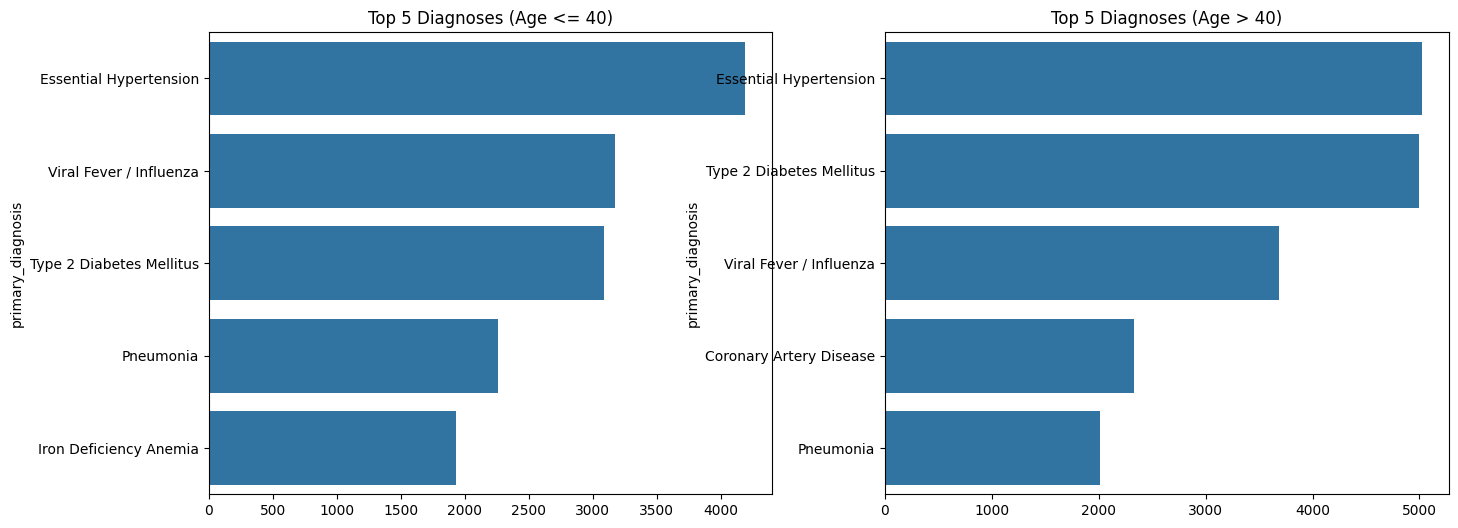

In [94]:
under_40 = df[df['age'] <= 40]['primary_diagnosis'].value_counts().head(5)
over_40 = df[df['age'] > 40]['primary_diagnosis'].value_counts().head(5)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(x=under_40.values, y=under_40.index, ax=axes[0])
axes[0].set_title('Top 5 Diagnoses (Age <= 40)')

sns.barplot(x=over_40.values, y=over_40.index, ax=axes[1])
axes[1].set_title('Top 5 Diagnoses (Age > 40)')

plt.show()

Essential Hypertension is the most common diagnosis in both age groups. For patients above 40, Type 2 Diabetes becomes almost as common as hypertension. Viral Fever remains among the top diagnoses in both groups. Coronary Artery Disease appears in the top five for patients above 40, while Iron Deficiency Anemia is more common in the younger group.

### Question 35: Multi-Panel Pie Chart Row (Smoking, Alcohol, Allergies)

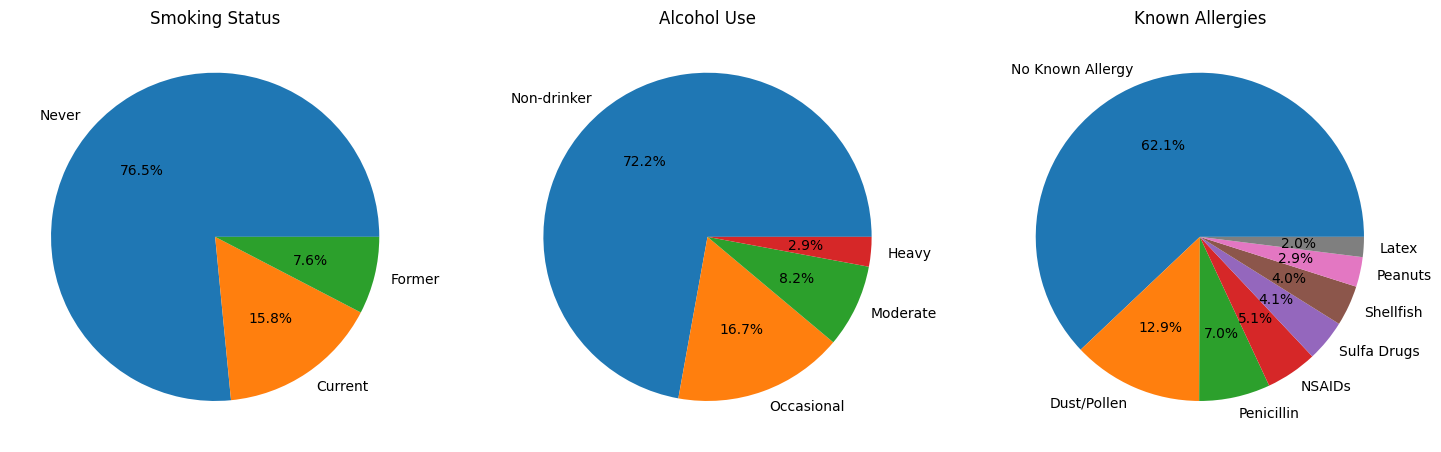

In [95]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

smoke = df['smoking_status'].value_counts()
axes[0].pie(smoke, labels=smoke.index, autopct='%1.1f%%')
axes[0].set_title('Smoking Status')

alcohol = df['alcohol_use'].value_counts()
axes[1].pie(alcohol, labels=alcohol.index, autopct='%1.1f%%')
axes[1].set_title('Alcohol Use')

allergy = df['known_allergy'].value_counts()
axes[2].pie(allergy, labels=allergy.index, autopct='%1.1f%%')
axes[2].set_title('Known Allergies')

plt.show()

Most patients have never smoked (76.5%), while 15.8% are current smokers and 7.6% are former smokers. Most patients also do not consume alcohol (72.2%), while 16.7% drink occasionally and only a small number drink heavily. Around 62.1% of patients have no known allergies. Among those with allergies, Dust/Pollen is the most common, followed by Penicillin and NSAIDs.

### Question 36: Horizontal Stacked Bar Chart (Payment Status by Insurance Provider)

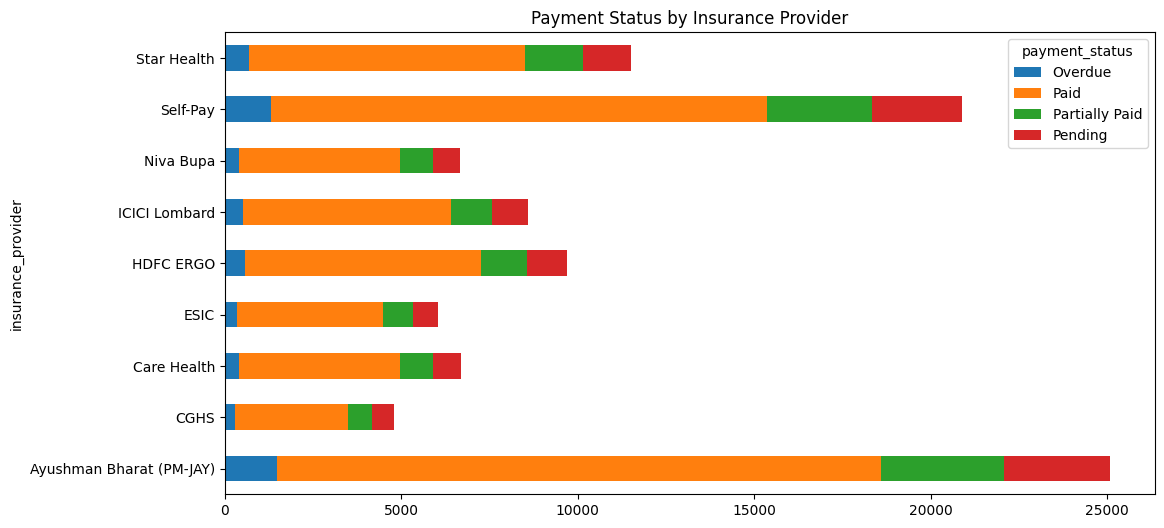

In [96]:
payment_insurance = pd.crosstab(df['insurance_provider'], df['payment_status'])
payment_insurance.plot(kind='barh', stacked=True, figsize=(12, 6))
plt.title('Payment Status by Insurance Provider')
plt.show()

Most payments are completed across all insurance providers, as the Paid category has the largest share. Ayushman Bharat (PM-JAY) has the highest number of payments, followed by Self-Pay. Some payments are still partially paid, pending, or overdue. Self-Pay also has a high number of pending payments compared to most other providers.

### Question 37: Dual Bar Comparison Chart (Departments: Emergency vs Elective)

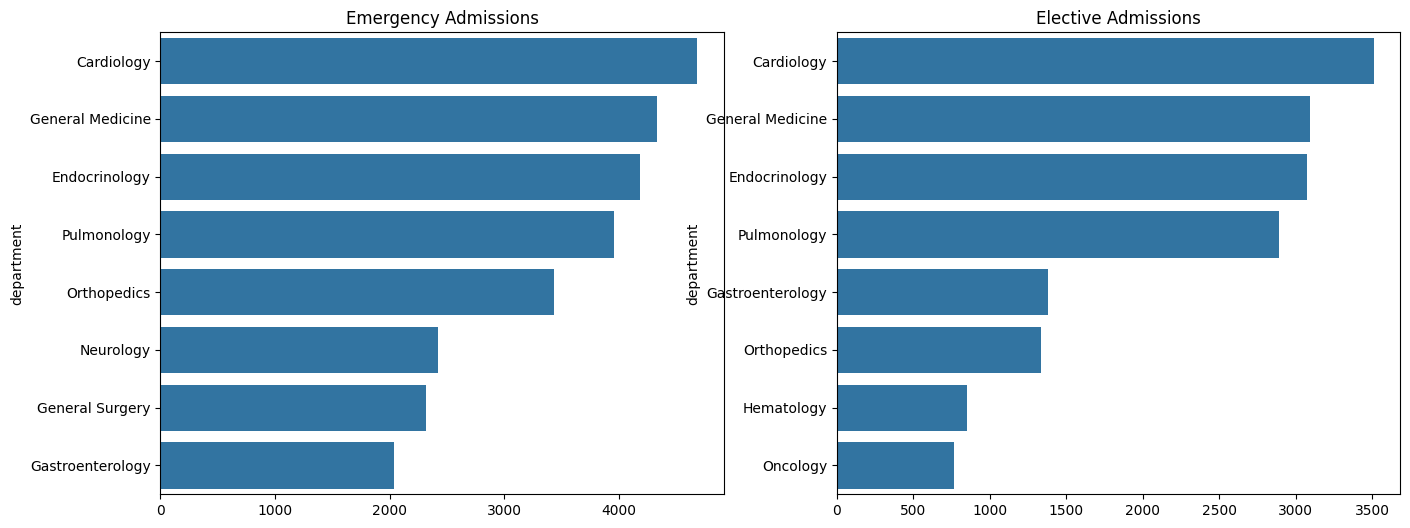

In [97]:
emergency_dept = df[df['admission_type'] == 'Emergency']['department'].value_counts().head(8)
elective_dept = df[df['admission_type'] == 'Elective']['department'].value_counts().head(8)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(x=emergency_dept.values, y=emergency_dept.index, ax=axes[0])
axes[0].set_title('Emergency Admissions')

sns.barplot(x=elective_dept.values, y=elective_dept.index, ax=axes[1])
axes[1].set_title('Elective Admissions')

plt.show()

this one also
Cardiology has the highest number of admissions in both emergency and elective cases. General Medicine, Endocrinology, and Pulmonology also handle a large number of patients in both categories. In emergency admissions, Orthopedics and Neurology are also common, while in elective admissions, Gastroenterology, Orthopedics, and Hematology have fewer patients.

### Question 38: Age Group Pie Chart

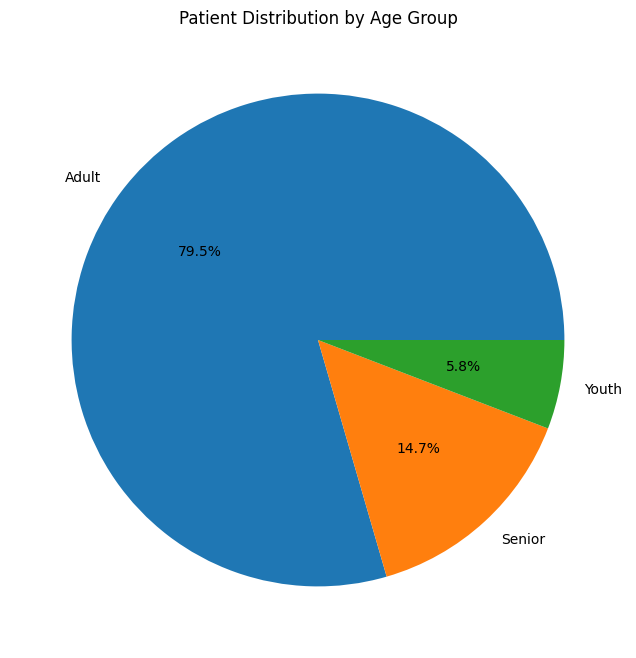

In [98]:
age_group_counts = df['age_group'].value_counts()
plt.figure(figsize=(8, 8))
plt.pie(age_group_counts, labels=age_group_counts.index, autopct='%1.1f%%')
plt.title('Patient Distribution by Age Group')
plt.show()

Most patients are adults, making up 79.5% of the total patient population. Senior patients account for 14.7%, while young patients make up only 5.8%.

### Question 39: Horizontal Bar and Pie Comparison (Patient State Distributions)

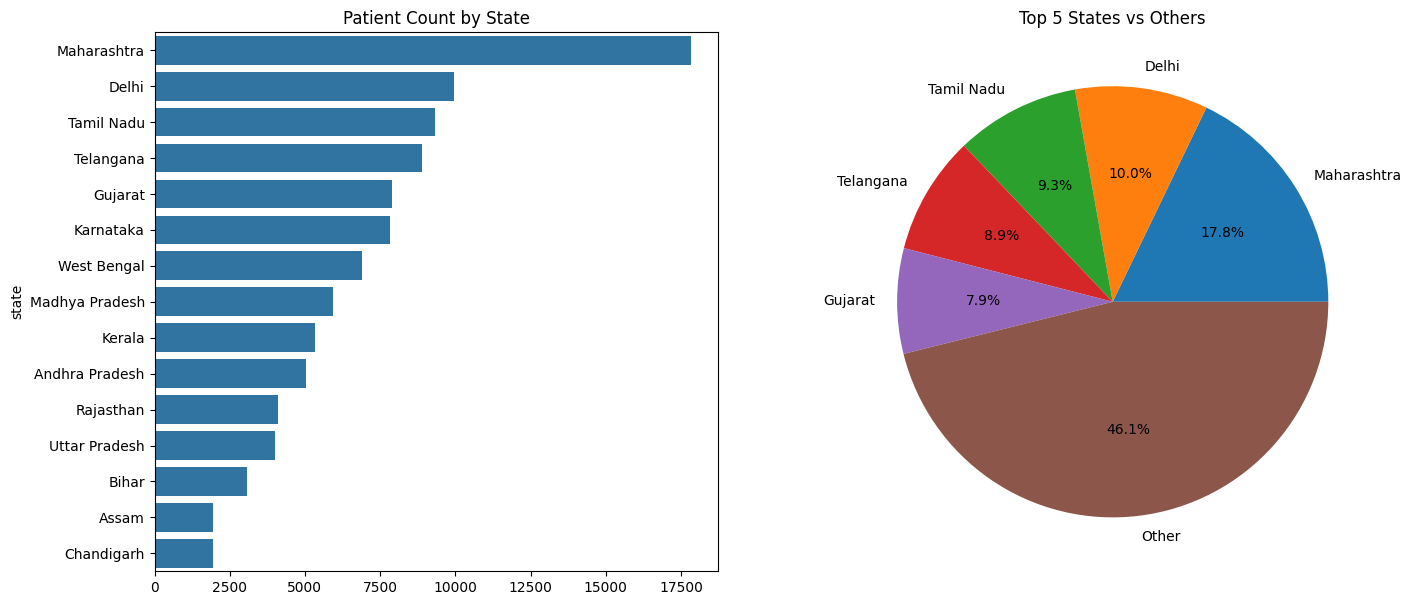

In [99]:
state_counts = df['state'].value_counts()
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

sns.barplot(x=state_counts.values, y=state_counts.index, ax=axes[0])
axes[0].set_title('Patient Count by State')

top_5 = state_counts.head(5)
other_val = state_counts.iloc[5:].sum()
pie_data = pd.concat([top_5, pd.Series({'Other': other_val})])

axes[1].pie(pie_data, labels=pie_data.index, autopct='%1.1f%%')
axes[1].set_title('Top 5 States vs Others')

plt.show()


Maharashtra has the highest number of patients, followed by Delhi, Tamil Nadu, Telangana, and Gujarat. These five states contribute a significant share of the total patients. Maharashtra alone accounts for 17.8%, while Delhi contributes 10%. The remaining states together make up 46.1% of the patient population.

### Question 40: Three-Panel Grid Comparison (BMI, Risk Score & Categories)

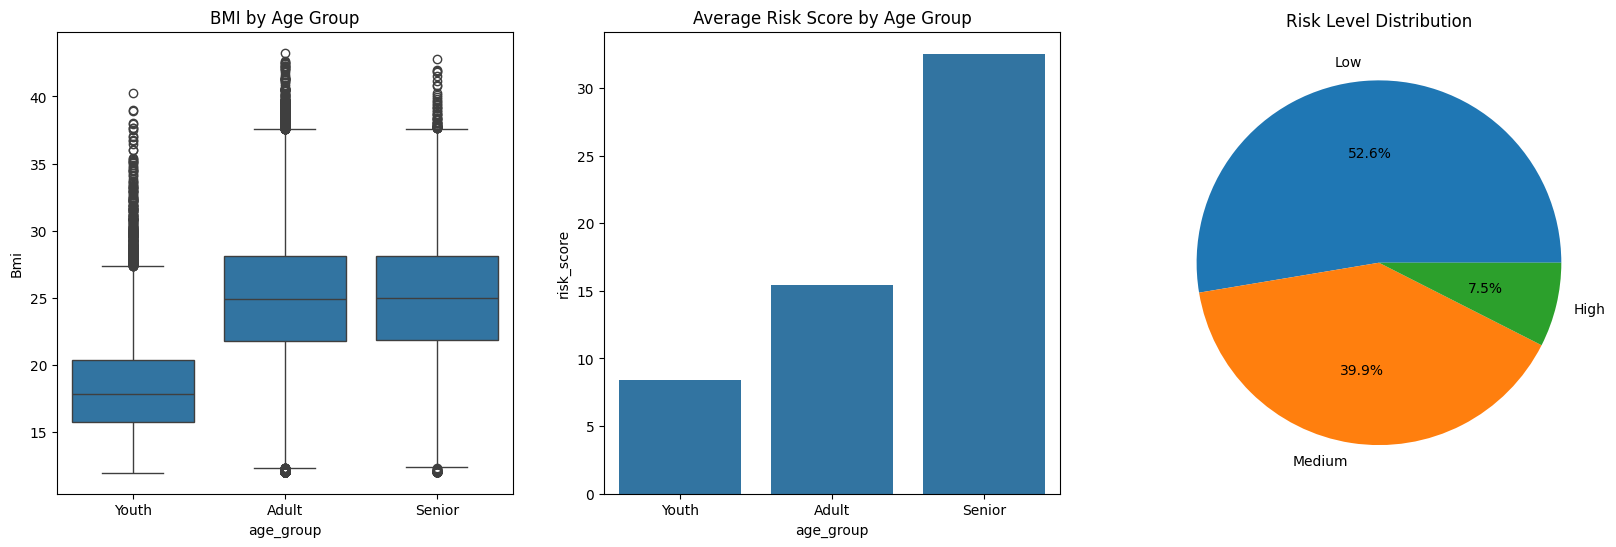

In [100]:
df['risk_category'] = pd.cut(df['risk_score'], bins=[0, 15, 35, 100], labels=['Low', 'Medium', 'High'])
risk_cat_counts = df['risk_category'].value_counts()

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

sns.boxplot(data=df, x='age_group', y='Bmi', ax=axes[0])
axes[0].set_title('BMI by Age Group')

sns.barplot(data=df, x='age_group', y='risk_score', ax=axes[1], errorbar=None)
axes[1].set_title('Average Risk Score by Age Group')

axes[2].pie(risk_cat_counts, labels=risk_cat_counts.index, autopct='%1.1f%%')
axes[2].set_title('Risk Level Distribution')

plt.show()

The chart shows that adults and senior patients have a higher BMI than young patients. The average risk score also increases with age, with senior patients having the highest risk score, followed by adults and youth. In the overall patient population, 52.6% have a low risk level, 39.9% have a medium risk level, and only 7.5% have a high risk level.